In [1]:
# ================================================================
# MACHINE LEARNING PRACTICAL
# HEART DISEASE CLASSIFICATION
# ================================================================

# ------------------------------------------------
#  Import Required Libraries
# ------------------------------------------------

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)


In [2]:
# ------------------------------------------------
# Load the Dataset
# ------------------------------------------------

df = pd.read_csv("heart.csv")

In [3]:
# ------------------------------------------------
# First Five rows of the dataset
# ------------------------------------------------

print("First 5 rows of the dataset:")
print(df.head())

print("\nShape of dataset:")
print(df.shape)

print("\nColumn names:")
print(df.columns)

print("\nDataset information:")
print(df.info())

print("\nStatistical description:")
print(df.describe())

First 5 rows of the dataset:
   age  sex  cp  trestbps  chol  fbs  restecg  thalach  exang  oldpeak  slope  \
0   52    1   0       125   212    0        1      168      0      1.0      2   
1   53    1   0       140   203    1        0      155      1      3.1      0   
2   70    1   0       145   174    0        1      125      1      2.6      0   
3   61    1   0       148   203    0        1      161      0      0.0      2   
4   62    0   0       138   294    1        1      106      0      1.9      1   

   ca  thal  target  
0   2     3       0  
1   0     3       0  
2   0     3       0  
3   1     3       0  
4   3     2       0  

Shape of dataset:
(1025, 14)

Column names:
Index(['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach',
       'exang', 'oldpeak', 'slope', 'ca', 'thal', 'target'],
      dtype='object')

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1025 entries, 0 to 1024
Data columns (total 14 columns):
 #   Column    Non-

In [4]:
# ------------------------------------------------
# Check Missing Values
# ------------------------------------------------

print("\nMissing values in each column:")
print(df.isnull().sum())


Missing values in each column:
age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          0
thal        0
target      0
dtype: int64


In [5]:
# ------------------------------------------------
# Check Duplicate Values
# ------------------------------------------------

print("\nNumber of duplicate rows:")
print(df.duplicated().sum())
 
# Remove duplicate rows if present
df = df.drop_duplicates()

print("\nShape after removing duplicates:")
print(df.shape)



Number of duplicate rows:
723

Shape after removing duplicates:
(302, 14)


In [6]:
# ------------------------------------------------
# Check Target Variable
# ------------------------------------------------

print("\nTarget value distribution:")
print(df["target"].value_counts())


Target value distribution:
target
1    164
0    138
Name: count, dtype: int64


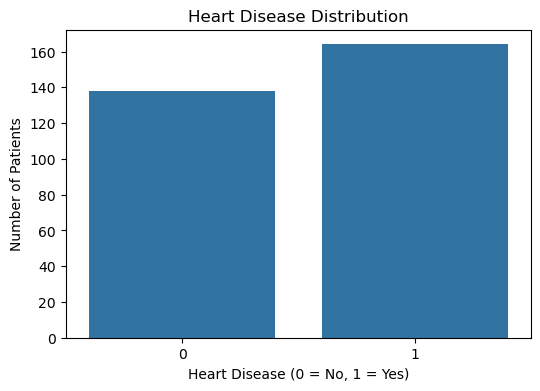

In [7]:
# ------------------------------------------------
#  Visualize Target Distribution
# ------------------------------------------------

plt.figure(figsize=(6, 4))

sns.countplot(x="target", data=df)

plt.title("Heart Disease Distribution")
plt.xlabel("Heart Disease (0 = No, 1 = Yes)")
plt.ylabel("Number of Patients")

plt.show()

In [8]:
# ------------------------------------------------
# Separate Features and Target
# ------------------------------------------------

X = df.drop("target", axis=1)

y = df["target"]


print("\nFeatures:")
print(X.head())

print("\nTarget:")
print(y.head())


Features:
   age  sex  cp  trestbps  chol  fbs  restecg  thalach  exang  oldpeak  slope  \
0   52    1   0       125   212    0        1      168      0      1.0      2   
1   53    1   0       140   203    1        0      155      1      3.1      0   
2   70    1   0       145   174    0        1      125      1      2.6      0   
3   61    1   0       148   203    0        1      161      0      0.0      2   
4   62    0   0       138   294    1        1      106      0      1.9      1   

   ca  thal  
0   2     3  
1   0     3  
2   0     3  
3   1     3  
4   3     2  

Target:
0    0
1    0
2    0
3    0
4    0
Name: target, dtype: int64


In [9]:
# ------------------------------------------------
#  Split Dataset into Training and Testing
# ------------------------------------------------

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("\nTraining data shape:")
print(X_train.shape)

print("\nTesting data shape:")
print(X_test.shape)



Training data shape:
(241, 13)

Testing data shape:
(61, 13)


In [10]:
# ------------------------------------------------
#  Feature Scaling
# ------------------------------------------------

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)

X_test_scaled = scaler.transform(X_test)

In [11]:
# ------------------------------------------------
#  Create Classification Models
# ------------------------------------------------

logistic_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

knn_model = KNeighborsClassifier(
    n_neighbors=5
)

svm_model = SVC(
    kernel="rbf",
    random_state=42
)

decision_tree_model = DecisionTreeClassifier(
    random_state=42
)

In [12]:
# ------------------------------------------------
# Train Logistic Regression
# ------------------------------------------------

logistic_model.fit(
    X_train_scaled,
    y_train
)

logistic_prediction = logistic_model.predict(
    X_test_scaled
)


In [13]:
# ------------------------------------------------
# Train KNN
# ------------------------------------------------

knn_model.fit(
    X_train_scaled,
    y_train
)

knn_prediction = knn_model.predict(
    X_test_scaled
)


In [14]:
# ------------------------------------------------
# Train SVM
# ------------------------------------------------

svm_model.fit(
    X_train_scaled,
    y_train
)

svm_prediction = svm_model.predict(
    X_test_scaled
)

In [15]:
# ------------------------------------------------
# Train Decision Tree
# ------------------------------------------------
decision_tree_model.fit(
    X_train,
    y_train
)

decision_tree_prediction = decision_tree_model.predict(
    X_test
)


In [16]:
# ------------------------------------------------
#  Calculate Model Performance
# ------------------------------------------------

models = {
    "Logistic Regression": (
        y_test,
        logistic_prediction
    ),

    "KNN": (
        y_test,
        knn_prediction
    ),

    "SVM": (
        y_test,
        svm_prediction
    ),

    "Decision Tree": (
        y_test,
        decision_tree_prediction
    )
}


results = []


for model_name, (actual, predicted) in models.items():

    accuracy = accuracy_score(
        actual,
        predicted
    )

    precision = precision_score(
        actual,
        predicted
    )

    recall = recall_score(
        actual,
        predicted
    )

    f1 = f1_score(
        actual,
        predicted
    )

    results.append({
        "Model": model_name,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1 Score": f1
    })


In [17]:

# Display Comparison

results_df = pd.DataFrame(results)

print("Model performance comparison")

print(results_df)


Model performance comparison
                 Model  Accuracy  Precision    Recall  F1 Score
0  Logistic Regression  0.803279   0.800000  0.848485  0.823529
1                  KNN  0.786885   0.777778  0.848485  0.811594
2                  SVM  0.770492   0.771429  0.818182  0.794118
3        Decision Tree  0.803279   0.818182  0.818182  0.818182


In [18]:

# Classification Reports

print("Logistic regression")
print(
    classification_report(
        y_test,
        logistic_prediction
    )
)

Logistic regression
              precision    recall  f1-score   support

           0       0.81      0.75      0.78        28
           1       0.80      0.85      0.82        33

    accuracy                           0.80        61
   macro avg       0.80      0.80      0.80        61
weighted avg       0.80      0.80      0.80        61



In [ ]:
print("KNN")

print(
    classification_report(
        y_test,
        knn_prediction
    )
)


KNN
              precision    recall  f1-score   support

           0       0.80      0.71      0.75        28
           1       0.78      0.85      0.81        33

    accuracy                           0.79        61
   macro avg       0.79      0.78      0.78        61
weighted avg       0.79      0.79      0.79        61



In [ ]:
print("SVM")

print(
    classification_report(
        y_test,
        svm_prediction
    )
)


SVM
              precision    recall  f1-score   support

           0       0.77      0.71      0.74        28
           1       0.77      0.82      0.79        33

    accuracy                           0.77        61
   macro avg       0.77      0.77      0.77        61
weighted avg       0.77      0.77      0.77        61



In [ ]:
print("DECISION TREE")

print(
    classification_report(
        y_test,
        decision_tree_prediction
    )
)


DECISION TREE
              precision    recall  f1-score   support

           0       0.79      0.79      0.79        28
           1       0.82      0.82      0.82        33

    accuracy                           0.80        61
   macro avg       0.80      0.80      0.80        61
weighted avg       0.80      0.80      0.80        61



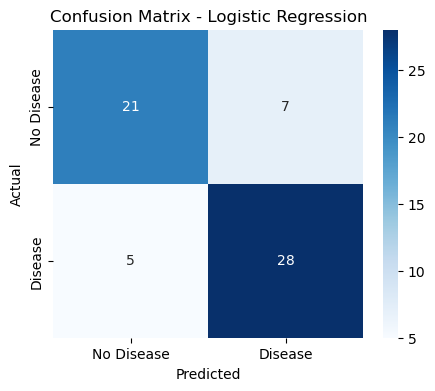

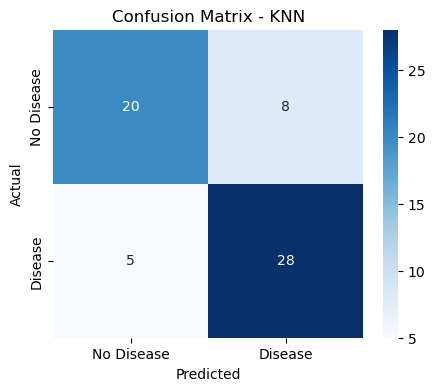

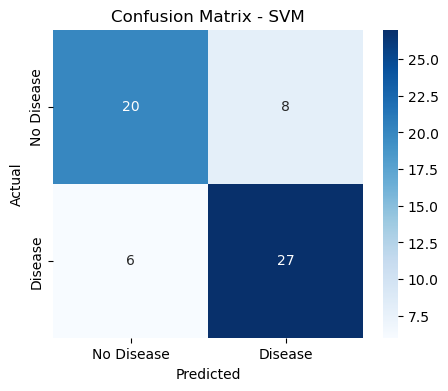

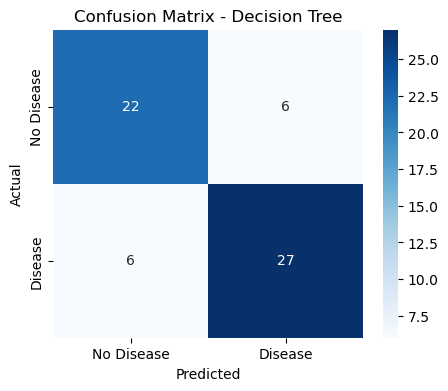

In [ ]:
#  Confusion Matrices

predictions = {
    "Logistic Regression": logistic_prediction,
    "KNN": knn_prediction,
    "SVM": svm_prediction,
    "Decision Tree": decision_tree_prediction
}


for model_name, prediction in predictions.items():

    cm = confusion_matrix(
        y_test,
        prediction
    )

    plt.figure(figsize=(5, 4))

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=["No Disease", "Disease"],
        yticklabels=["No Disease", "Disease"]
    )

    plt.title(
        "Confusion Matrix - " + model_name
    )

    plt.xlabel("Predicted")
    plt.ylabel("Actual")

    plt.show()


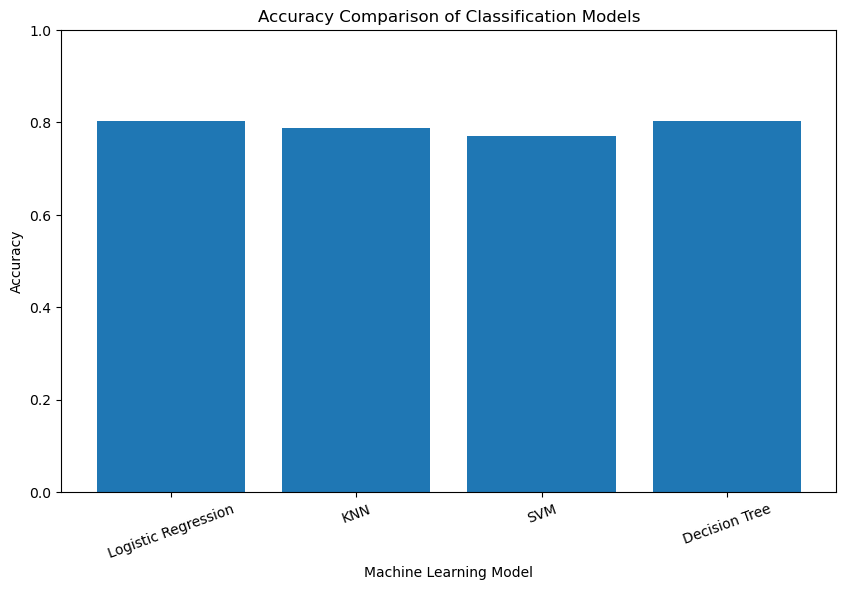

In [ ]:
# Accuracy Comparison Graph

plt.figure(figsize=(10, 6))

plt.bar(
    results_df["Model"],
    results_df["Accuracy"]
)

plt.title(
    "Accuracy Comparison of Classification Models"
)

plt.xlabel("Machine Learning Model")

plt.ylabel("Accuracy")

plt.ylim(0, 1)

plt.xticks(rotation=20)

plt.show()

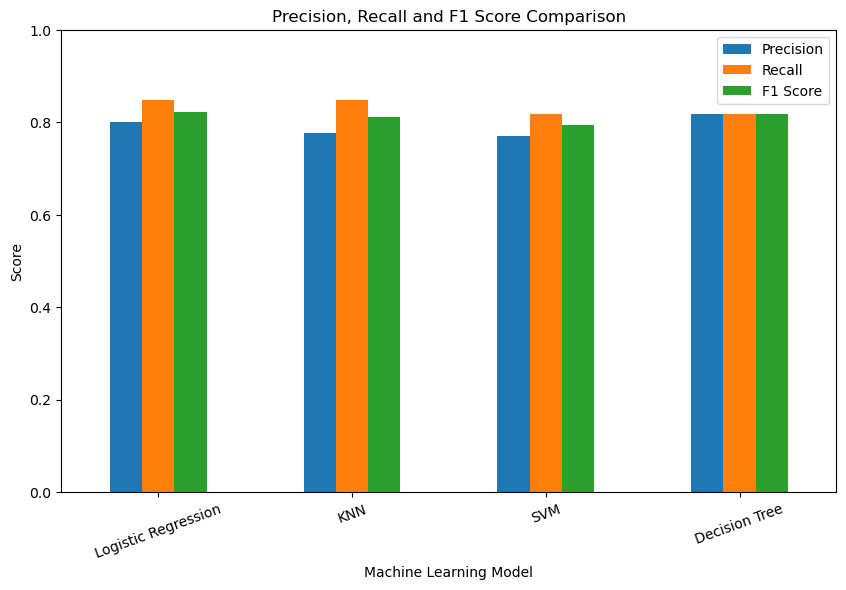

In [ ]:
#  Precision, Recall and F1 Comparison

results_plot = results_df.set_index("Model")

results_plot[
    ["Precision", "Recall", "F1 Score"]
].plot(
    kind="bar",
    figsize=(10, 6)
)

plt.title(
    "Precision, Recall and F1 Score Comparison"
)

plt.xlabel("Machine Learning Model")

plt.ylabel("Score")

plt.ylim(0, 1)

plt.xticks(rotation=20)

plt.legend()

plt.show()

In [ ]:

#  Find Best Model

best_model = results_df.loc[
    results_df["Accuracy"].idxmax()
]

print("Best Model")

print(
    "Best Model:",
    best_model["Model"]
)

print(
    "Accuracy:",
    round(best_model["Accuracy"] * 100, 2),
    "%"
)

print(
    "Precision:",
    round(best_model["Precision"] * 100, 2),
    "%"
)

print(
    "Recall:",
    round(best_model["Recall"] * 100, 2),
    "%"
)

print(
    "F1 Score:",
    round(best_model["F1 Score"] * 100, 2),
    "%"
)



BEST MODEL
Best Model: Logistic Regression
Accuracy: 80.33 %
Precision: 80.0 %
Recall: 84.85 %
F1 Score: 82.35 %
